In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h3
import folium
import matplotlib.cm as cm
import matplotlib.colors as colors

In [3]:
#loading data_orders dataset
df = pd.read_csv('data_orders.csv')
df.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10716 entries, 0 to 10715
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_datetime                 10716 non-null  object 
 1   origin_longitude               10716 non-null  float64
 2   origin_latitude                10716 non-null  float64
 3   m_order_eta                    2814 non-null   float64
 4   order_gk                       10716 non-null  int64  
 5   order_status_key               10716 non-null  int64  
 6   is_driver_assigned_key         10716 non-null  int64  
 7   cancellations_time_in_seconds  7307 non-null   float64
dtypes: float64(4), int64(3), object(1)
memory usage: 669.9+ KB


In [5]:
print(df['order_status_key'].value_counts())

order_status_key
4    7307
9    3409
Name: count, dtype: int64


In [6]:
print(df['is_driver_assigned_key'].value_counts())

is_driver_assigned_key
0    7902
1    2814
Name: count, dtype: int64


In [7]:
table = pd.crosstab(df['order_status_key'], df['is_driver_assigned_key'])
print(table)

is_driver_assigned_key     0     1
order_status_key                  
4                       4496  2811
9                       3406     3


In [8]:
conditions = [
    (df['order_status_key'] == 4) & (df['is_driver_assigned_key'] == 0),
    (df['order_status_key'] == 4) & (df['is_driver_assigned_key'] == 1),
    (df['order_status_key'] == 9) 
]

labels = [
    'Cancelled by Client\n(no driver assigned)', 
    'Cancelled by Client\n(driver assigned)',
    'Rejected by System'
]

df['failure_reason'] = np.select(conditions, labels, default='Unknown')

In [9]:
counts = df['failure_reason'].value_counts()
print(counts)

failure_reason
Cancelled by Client\n(no driver assigned)    4496
Rejected by System                           3409
Cancelled by Client\n(driver assigned)       2811
Name: count, dtype: int64


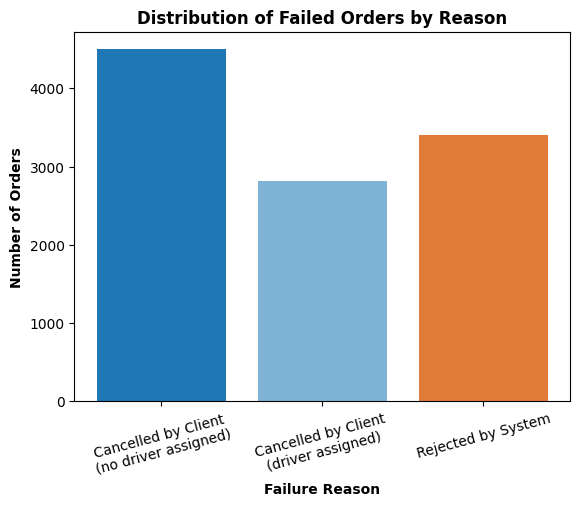

In [10]:
#plotting the bar chart

order = ['Cancelled by Client\n(no driver assigned)', 
    'Cancelled by Client\n(driver assigned)',
    'Rejected by System']

counts_ordered = counts.reindex(order)

colors = ['#1f77b4', '#7fb3d5', '#e07b39']

plt.bar(counts_ordered.index, counts_ordered.values, color=colors)
plt.title('Distribution of Failed Orders by Reason', fontweight='bold')
plt.xlabel('Failure Reason', fontweight='bold')
plt.ylabel('Number of Orders', fontweight='bold')
plt.xticks(rotation=15)
plt.show()

Client-initiated cancellations before driver assignment are the single largest failure category with 4496 orders, suggesting that many customers abandon their request very early, even before the system finds them a match. System rejections which are about 3406 are the second-largest, pointing to matching/supply constraints. Cancellations after a driver is already assigned are the smallest category which are about 2811, meaning once a match is made, most orders do go through. /

In [11]:
df['order_datetime'].head()

0    18:08:07
1    20:57:32
2    12:07:50
3    13:50:20
4    21:24:45
Name: order_datetime, dtype: object

In [12]:
df['order_datetime'] = pd.to_datetime(df['order_datetime'], format='%H:%M:%S')
df['hour'] = df['order_datetime'].dt.hour

In [13]:
df['hour'].value_counts().sort_index()

hour
0      683
1      471
2      555
3      513
4      152
5       67
6      159
7      447
8     1082
9      412
10     170
11     193
12     256
13     366
14     256
15     439
16     356
17     541
18     414
19     317
20     469
21     846
22     716
23     836
Name: count, dtype: int64

In [14]:
hourly_reason = pd.crosstab(df['hour'], df['failure_reason'])
hourly_reason

failure_reason,Cancelled by Client\n(driver assigned),Cancelled by Client\n(no driver assigned),Rejected by System
hour,,,
0,120,298,265
1,88,219,164
2,78,237,240
3,64,224,225
4,41,50,61
5,25,15,27
6,47,67,45
7,156,164,127
8,314,413,355


In [15]:
hourly_reason_pct = hourly_reason.div(hourly_reason.sum(axis=1), axis=0) * 100
hourly_reason_pct

failure_reason,Cancelled by Client\n(driver assigned),Cancelled by Client\n(no driver assigned),Rejected by System
hour,,,
0,17.569546,43.631040,38.799414
1,18.683652,46.496815,34.819533
2,14.054054,42.702703,43.243243
3,12.475634,43.664717,43.859649
4,26.973684,32.894737,40.131579
5,37.313433,22.388060,40.298507
6,29.559748,42.138365,28.301887
7,34.899329,36.689038,28.411633
8,29.020333,38.170055,32.809612


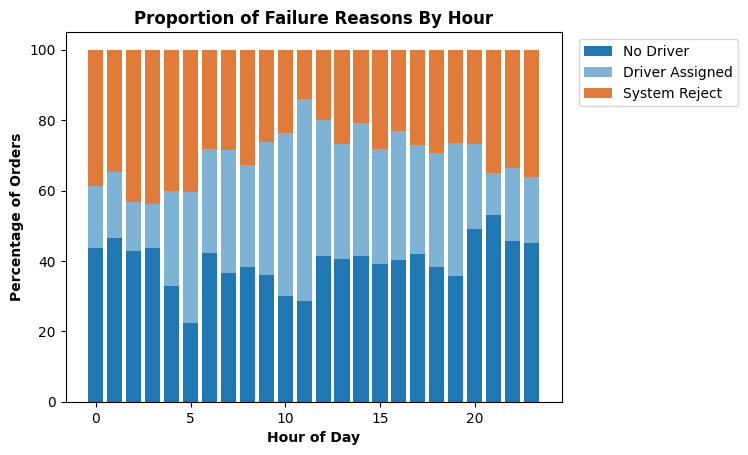

In [16]:
#plotting the bar chart
hours = hourly_reason_pct.index

bar1 = hourly_reason_pct['Cancelled by Client\n(no driver assigned)']
bar2 = hourly_reason_pct['Cancelled by Client\n(driver assigned)']
bar3 = hourly_reason_pct['Rejected by System']

plt.bar(hours, bar1, color='#1f77b4', label='No Driver')
plt.bar(hours, bar2, bottom=bar1, color='#7fb3d5', label='Driver Assigned')
plt.bar(hours, bar3, bottom=bar1 + bar2, color='#e07b39', label='System Reject')

plt.title('Proportion of Failure Reasons By Hour', fontweight='bold')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Percentage of Orders', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

The mix of failure types shifts meaningfully across the day. Midday hours, roughly 9am - 4pm, see a higher share of post-assignment client cancellations, suggesting once drivers are matched, arrival delays or changes plans are most likely mid-day. Late-night and early-morning hours hsow a higher share of system rejections and pre-assignment cancellations, consistent with reduced dtiver supply overnight making both matching failures and client impatience more common. 

In [17]:
df.groupby('order_status_key')['cancellations_time_in_seconds'].count()

order_status_key
4    7307
9       0
Name: cancellations_time_in_seconds, dtype: int64

In [18]:
df['cancellations_time_in_seconds'].describe()

count    7307.000000
mean      157.892021
std       213.366963
min         3.000000
25%        45.000000
50%        98.000000
75%       187.500000
max      4303.000000
Name: cancellations_time_in_seconds, dtype: float64

In [19]:
Q1 = df['cancellations_time_in_seconds'].quantile(0.25)
Q3 = df['cancellations_time_in_seconds'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5*IQR

outliers = df[df['cancellations_time_in_seconds'] > upper_bound]
print(f"Upper bound: {upper_bound}")
print(f"Number of outliers: {len(outliers)}")

Upper bound: 401.25
Number of outliers: 592


In [20]:
outliers['hour'].value_counts().sort_index()

hour
0     34
1     17
2     26
3     19
4      9
5      6
6     12
7     25
8     41
9     26
10    15
11    26
12    24
13    26
14    20
15    28
16    25
17    40
18    30
19    22
20    23
21    23
22    32
23    43
Name: count, dtype: int64

In [21]:
df_filtered = df[df['cancellations_time_in_seconds'] <= upper_bound]

In [22]:
hourly_avg = df_filtered.groupby(['hour', 'is_driver_assigned_key'])['cancellations_time_in_seconds'].mean()

In [23]:
hourly_avg

hour  is_driver_assigned_key
0     0                         103.453925
      1                         146.131868
1     0                          98.132420
      1                         132.985915
2     0                         101.205128
      1                         140.527273
3     0                         102.174888
      1                         115.326087
4     0                          90.000000
      1                         121.125000
5     0                         121.800000
      1                         100.368421
6     0                         101.384615
      1                          89.675676
7     0                         108.549383
      1                         122.962406
8     0                         110.412346
      1                         127.540925
9     0                         108.724138
      1                         127.781955
10    0                          66.200000
      1                         102.184615
11    0                  

In [24]:
hourly_avg_wide = hourly_avg.unstack()
hourly_avg_wide

is_driver_assigned_key,0,1
hour,,
0,103.453925,146.131868
1,98.132420,132.985915
2,101.205128,140.527273
3,102.174888,115.326087
4,90.000000,121.125000
5,121.800000,100.368421
6,101.384615,89.675676
7,108.549383,122.962406
8,110.412346,127.540925


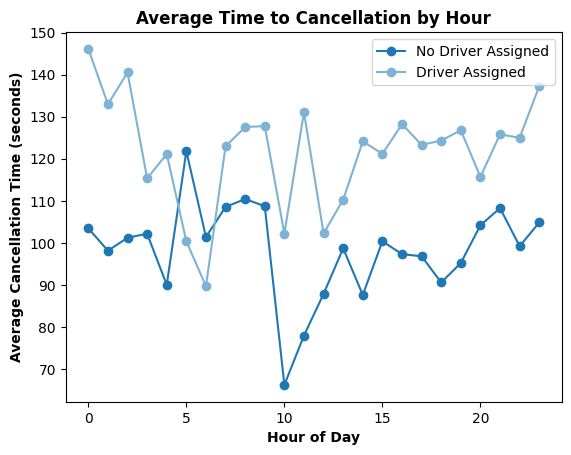

In [25]:
hourly_avg_wide.columns = ['No Driver Assigned', 'Driver Assigned']

plt.plot(hourly_avg_wide.index, hourly_avg_wide['No Driver Assigned'], color='#1f77b4', label='No Driver Assigned', marker='o')
plt.plot(hourly_avg_wide.index, hourly_avg_wide['Driver Assigned'], color='#7fb3d5', label='Driver Assigned', marker='o')

plt.title('Average Time to Cancellation by Hour', fontweight='bold')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Average Cancellation Time (seconds)', fontweight='bold')
plt.legend()
plt.show()

Across nearly all hours, clients wait longer to cancel once a driver has been assigned, likely because they can see progress (a driver en route) rather than facing an indefinite wait. The gap is smallest overnight, i.e., hours 5-6, where the pattern briefly reverses, and largest around late morning (hour 10-11), where without driver cancellations happen unusually fast. 

In [26]:
df['m_order_eta'].isnull().sum()

7902

In [27]:
df['m_order_eta'].describe()

count    2814.000000
mean      441.415423
std       288.006379
min        60.000000
25%       233.000000
50%       368.500000
75%       653.000000
max      1559.000000
Name: m_order_eta, dtype: float64

In [29]:
df.groupby('is_driver_assigned_key')['m_order_eta'].count()

is_driver_assigned_key
0       0
1    2814
Name: m_order_eta, dtype: int64

In [30]:
Q1 = df['m_order_eta'].quantile(0.25)
Q3 = df['m_order_eta'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

eta_outliers = df[df['m_order_eta'] > upper_bound]
print(f"Upper bound: {upper_bound}")
print(f"Number of outliers: {len(eta_outliers)}")

Upper bound: 1283.0
Number of outliers: 5


In [31]:
df_eta_filtered = df[df['m_order_eta'] <= upper_bound]

In [32]:
hourly_eta = df_eta_filtered.groupby('hour')['m_order_eta'].mean()

In [33]:
hourly_eta

hour
0     357.959016
1     324.750000
2     391.012821
3     388.093750
4     299.658537
5     411.120000
6     427.148936
7     578.832258
8     634.543131
9     504.891026
10    355.556962
11    390.954955
12    440.787879
13    428.025000
14    387.835052
15    454.790210
16    440.568182
17    513.481928
18    419.186567
19    361.268908
20    300.096491
21    333.852941
22    365.979730
23    408.429487
Name: m_order_eta, dtype: float64

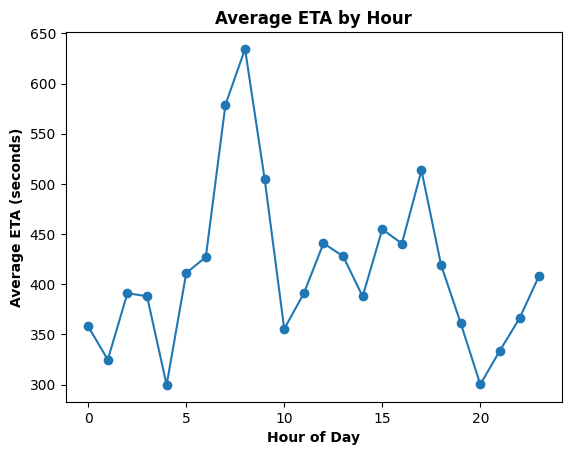

In [34]:
plt.plot(hourly_eta.index, hourly_eta.values, color='#1f77b4', marker='o')
plt.title('Average ETA by Hour', fontweight='bold')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Average ETA (seconds)', fontweight='bold')
plt.show()

In [35]:
df[['origin_latitude', 'origin_longitude']].isnull().sum()

origin_latitude     0
origin_longitude    0
dtype: int64

In [37]:
!pip install h3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 848.1/848.1 kB 22.3 MB/s  0:00:00


In [39]:
print(h3.__version__)

4.5.0


In [41]:
df['hex_id'] = df.apply(lambda row: h3.latlng_to_cell(row['origin_latitude'], row['origin_longitude'], 8), axis=1)

In [42]:
df['hex_id'].head()

0    88195d2b03fffff
1    88195d2b19fffff
2    88195d2b1dfffff
3    88195d7497fffff
4    88195d2b1dfffff
Name: hex_id, dtype: object

In [46]:
cum_pct = df['hex_id'].value_counts().cumsum() / len(df['hex_id']) * 100

In [47]:
cum_pct

hex_id
88195d2b1dfffff     13.969765
88195d2b1bfffff     22.088466
88195d2b15fffff     29.311310
88195d2b11fffff     35.908921
88195d2b19fffff     42.133259
                      ...    
88195d2821fffff     99.962673
88195d3993fffff     99.972004
88195d2b69fffff     99.981336
88195d74d5fffff     99.990668
88195d2807fffff    100.000000
Name: count, Length: 144, dtype: float64

In [48]:
n_hexagons = (cum_pct < 80).sum() + 1
print(n_hexagons)

24


In [49]:
hex_counts = df['hex_id'].value_counts().reset_index()
hex_counts.columns = ['hex_id', 'fail_count']

In [50]:
hex_counts.head()

,hex_id,fail_count
0,88195d2b1dfffff,1497
1,88195d2b1bfffff,870
2,88195d2b15fffff,774
3,88195d2b11fffff,707
4,88195d2b19fffff,667


In [51]:
h3.cell_to_boundary(hex_counts['hex_id'][0])

((51.46233424112638, -0.9674195894273544),
 (51.46108611918585, -0.9741522492296638),
 (51.45658471409391, -0.9753174349705722),
 (51.453331691922436, -0.9697507654750164),
 (51.45457984273566, -0.9630191652468775),
 (51.45908098683117, -0.9618531750496598))

In [53]:
center_lat = df['origin_latitude'].mean()
center_lng = df['origin_longitude'].mean()

m = folium.Map(location=[center_lat, center_lng], zoom_start=12)

In [54]:
m

In [59]:
norm = colors.Normalize(vmin=hex_counts['fail_count'].min(), vmax=hex_counts['fail_count'].max())
colormap = matplotlib.colormaps['YlOrRd']

def get_color(count):
    rgba = colormap(norm(count))
    return colors.to_hex(rgba)

In [61]:
print(get_color(1497))
print(get_color(42))

#800026
#fffbc2


In [62]:
for index, row in hex_counts.iterrows():
    boundary = h3.cell_to_boundary(row['hex_id'])
    color = get_color(row['fail_count'])
    
    folium.Polygon(
        locations=boundary,
        color=color,
        weight=1,
        fill=True,
        fill_color=color,
        fill_opacity=0.6,
        popup=f"Hex: {row['hex_id']}<br>Fails: {row['fail_count']}"
    ).add_to(m)

m